In [2]:
import os                                                     # environment variables
prefix = os.environ.get("CONDA_PREFIX") or os.path.dirname(os.sys.executable)   # e.g. C:\Users\...\envs\geoai-accra
lib = os.path.join(prefix, "Library")                         # conda's Windows library folder
os.environ["PATH"] = os.path.join(lib, "bin") + os.pathsep + os.environ["PATH"]   # DLLs for GDAL, PROJ, matplotlib
os.environ.setdefault("GDAL_DATA", os.path.join(lib, "share", "gdal"))           # GDAL settings files
os.environ.setdefault("PROJ_LIB", os.path.join(lib, "share", "proj"))            # coordinate system files
print("GDAL_DATA:", os.environ["GDAL_DATA"])                  # should now show a path, not None
print("PROJ_LIB: ", os.environ["PROJ_LIB"])                   # should show a path too

GDAL_DATA: C:\Users\ofosu\anaconda3\envs\dortmund-climate\Library\share\gdal
PROJ_LIB:  C:\Users\ofosu\anaconda3\envs\dortmund-climate\Library\share\proj


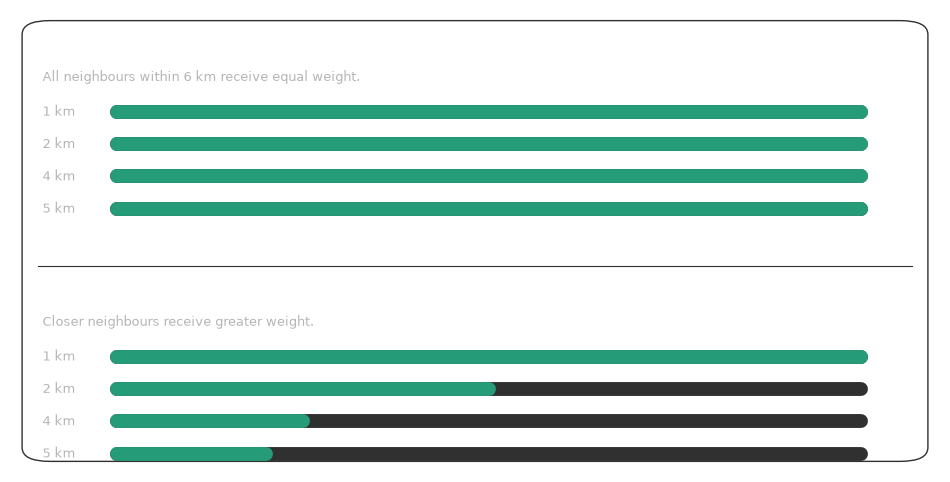

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# -----------------------------
# 1. Data
# -----------------------------
distances = ["1 km", "2 km", "4 km", "5 km"]

distance_band = [1.00, 1.00, 1.00, 1.00]
inverse_distance = [1.00, 0.50, 0.25, 0.20]

# -----------------------------
# 2. Figure and background
# -----------------------------
fig, ax = plt.subplots(figsize=(12, 6))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

# -----------------------------
# 3. Main rounded container
# -----------------------------
container = FancyBboxPatch(
    (0.15, 0.25),
    9.7,
    9.5,
    boxstyle="round,pad=0.02,rounding_size=0.3",
    facecolor="white",
    edgecolor="#303030",
    linewidth=1
)

ax.add_patch(container)

# -----------------------------
# 4. Drawing function
# -----------------------------
def draw_bars(title, subtitle, values, y_start):

    ax.text(
        0.35, y_start,
        title,
        color="white",
        fontsize=12,
        fontweight="bold",
        va="center"
    )

    ax.text(
        0.35, y_start - 0.65,
        subtitle,
        color="#b5b5b5",
        fontsize=9,
        va="center"
    )

    for i, (distance, value) in enumerate(
        zip(distances, values)
    ):

        y = y_start - 1.4 - i * 0.7

        # Distance label
        ax.text(
            0.35, y,
            distance,
            color="#b5b5b5",
            fontsize=9,
            va="center"
        )

        # Background bar
        ax.plot(
            [1.15, 9.15],
            [y, y],
            color="#303030",
            linewidth=10,
            solid_capstyle="round"
        )

        # Value bar
        ax.plot(
            [1.15, 1.15 + 8 * value],
            [y, y],
            color="#269B78",
            linewidth=10,
            solid_capstyle="round"
        )

        # Numerical value
        ax.text(
            9.35, y,
            f"{value:.2f}",
            color="white",
            fontsize=9,
            va="center"
        )


# -----------------------------
# 5. Distance band
# -----------------------------
draw_bars(
    "Distance band",
    "All neighbours within 6 km receive equal weight.",
    distance_band,
    9.2
)

# -----------------------------
# 6. Divider
# -----------------------------
ax.plot(
    [0.3, 9.7],
    [4.45, 4.45],
    color="#303030",
    linewidth=0.8
)

# -----------------------------
# 7. Inverse distance
# -----------------------------
draw_bars(
    "Inverse distance (power 1)",
    "Closer neighbours receive greater weight.",
    inverse_distance,
    3.9
)

# -----------------------------
# 8. Display
# -----------------------------
plt.savefig(
    "distance_vs_inverse_distance.png",
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

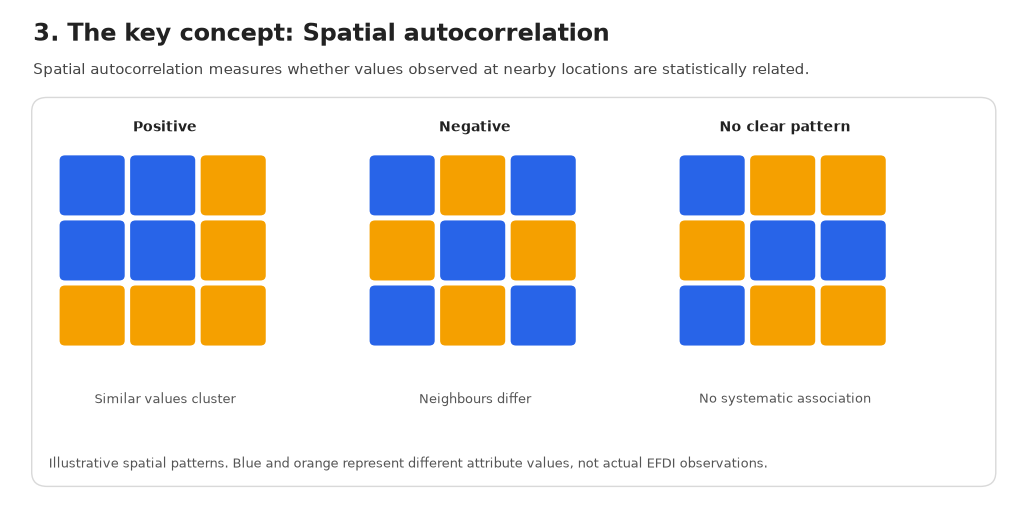

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

# --------------------------------
# 1. Create figure
# --------------------------------
fig, ax = plt.subplots(figsize=(13, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.set_xlim(0, 13)
ax.set_ylim(0, 7)
ax.axis("off")

# --------------------------------
# 2. Main heading and description
# --------------------------------
ax.text(
    0.3, 6.65,
    "3. The key concept: Spatial autocorrelation",
    fontsize=17,
    fontweight="bold",
    color="#222222",
    va="center"
)

ax.text(
    0.3, 6.15,
    "Spatial autocorrelation measures whether values observed at nearby locations are statistically related.",
    fontsize=10.5,
    color="#444444",
    va="center"
)

# --------------------------------
# 3. Main rounded container
# --------------------------------
container = FancyBboxPatch(
    (0.3, 0.35),
    12.4,
    5.4,
    boxstyle="round,pad=0.02,rounding_size=0.2",
    facecolor="white",
    edgecolor="#D9D9D9",
    linewidth=1
)

ax.add_patch(container)

# --------------------------------
# 4. Spatial pattern data
# --------------------------------
patterns = {
    "Positive": {
        "grid": [
            ["B", "B", "O"],
            ["B", "B", "O"],
            ["O", "O", "O"]
        ],
        "description": "Similar values cluster"
    },

    "Negative": {
        "grid": [
            ["B", "O", "B"],
            ["O", "B", "O"],
            ["B", "O", "B"]
        ],
        "description": "Neighbours differ"
    },

    "No clear pattern": {
        "grid": [
            ["B", "O", "O"],
            ["O", "B", "B"],
            ["B", "O", "O"]
        ],
        "description": "No systematic association"
    }
}

# Colours
colors = {
    "B": "#2864E8",
    "O": "#F5A000"
}

# --------------------------------
# 5. Draw spatial pattern grids
# --------------------------------
group_positions = [0.65, 4.65, 8.65]

square_size = 0.82
square_gap = 0.09
grid_top = 4.95

for (title, data), group_x in zip(
    patterns.items(), group_positions
):

    # Pattern heading
    ax.text(
        group_x + 1.35,
        5.35,
        title,
        fontsize=10,
        fontweight="bold",
        color="#222222",
        ha="center",
        va="center"
    )

    # Draw 3 x 3 grid
    for row in range(3):
        for col in range(3):

            value = data["grid"][row][col]

            x = group_x + col * (square_size + square_gap)
            y = grid_top - row * (square_size + square_gap)

            square = FancyBboxPatch(
                (x, y - square_size),
                square_size,
                square_size,
                boxstyle="round,pad=0.01,rounding_size=0.07",
                facecolor=colors[value],
                edgecolor="none"
            )

            ax.add_patch(square)

    # Description below each grid
    ax.text(
        group_x + 1.35,
        1.55,
        data["description"],
        fontsize=9,
        color="#555555",
        ha="center",
        va="center"
    )

# --------------------------------
# 6. Explanatory footer
# --------------------------------
ax.text(
    0.5,
    0.65,
    "Illustrative spatial patterns. Blue and orange represent different attribute values, not actual EFDI observations.",
    fontsize=9,
    color="#555555",
    va="center"
)

# --------------------------------
# 7. Save and display
# --------------------------------
plt.savefig(
    "spatial_autocorrelation_patterns.png",
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

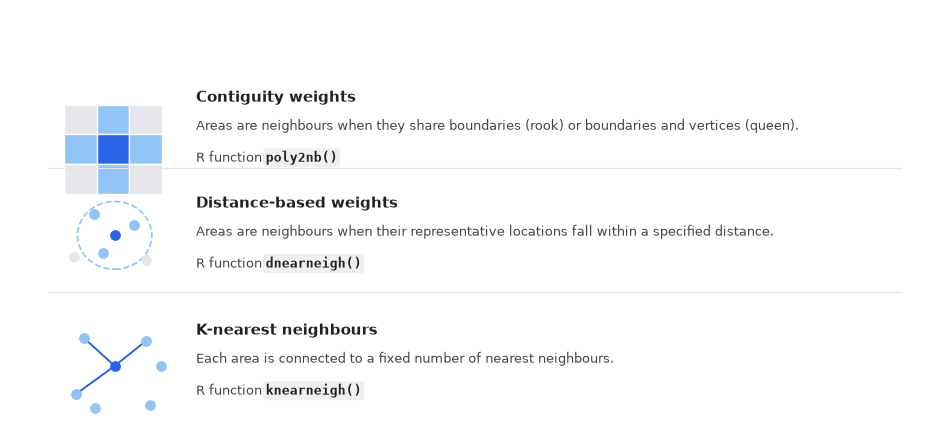

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.lines import Line2D

# --------------------------------
# 1. Figure and background
# --------------------------------
fig, ax = plt.subplots(figsize=(12, 5.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.set_xlim(0, 12)
ax.set_ylim(0, 6)
ax.axis("off")

# Colours
blue = "#2864E8"
light_blue = "#91C4F7"
light_grey = "#E5E7EB"
dark_text = "#222222"
description = "#444444"
divider = "#E5E5E5"

# --------------------------------
# 2. Drawing functions
# --------------------------------
def draw_text(x, y, title, subtitle, function):
    ax.text(
        x, y,
        title,
        fontsize=11,
        fontweight="bold",
        color=dark_text,
        va="center"
    )

    ax.text(
        x, y - 0.4,
        subtitle,
        fontsize=9.5,
        color=description,
        va="center"
    )

    ax.text(
        x, y - 0.85,
        "R function:",
        fontsize=9,
        color=description,
        va="center"
    )

    ax.text(
        x + 0.9, y - 0.85,
        function,
        fontsize=9,
        color=dark_text,
        fontweight="bold",
        va="center",
        family="monospace",
        bbox=dict(
            facecolor="#F0F0F0",
            edgecolor="none",
            boxstyle="round,pad=0.2"
        )
    )


# --------------------------------
# 3. Contiguity weights
# --------------------------------
grid_x = 0.7
grid_y = 4.65
cell_size = 0.42

grid = [
    ["grey", "light", "grey"],
    ["light", "blue", "light"],
    ["grey", "light", "grey"]
]

grid_colors = {
    "grey": light_grey,
    "light": light_blue,
    "blue": blue
}

for row in range(3):
    for col in range(3):

        square = Rectangle(
            (
                grid_x + col * cell_size,
                grid_y - row * cell_size - cell_size
            ),
            cell_size,
            cell_size,
            facecolor=grid_colors[grid[row][col]],
            edgecolor="white",
            linewidth=1
        )

        ax.add_patch(square)

draw_text(
    2.4,
    4.75,
    "Contiguity weights",
    "Areas are neighbours when they share boundaries (rook) or boundaries and vertices (queen).",
    "poly2nb()"
)

# --------------------------------
# 4. Distance-based weights
# --------------------------------
center_x = 1.35
center_y = 2.8

# Distance threshold circle
circle = Circle(
    (center_x, center_y),
    0.48,
    fill=False,
    edgecolor=light_blue,
    linewidth=1.2,
    linestyle="--"
)

ax.add_patch(circle)

# Central location
ax.scatter(
    center_x, center_y,
    color=blue,
    s=45,
    zorder=3
)

# Neighbour locations
distance_points = [
    (1.08, 3.1),
    (1.6, 2.95),
    (1.2, 2.55),
    (0.82, 2.5),
    (1.75, 2.45)
]

for x, y in distance_points:
    ax.scatter(
        x, y,
        color=light_blue if (
            (x - center_x)**2 + (y - center_y)**2
        )**0.5 <= 0.48 else light_grey,
        s=45,
        zorder=3
    )

draw_text(
    2.4,
    3.25,
    "Distance-based weights",
    "Areas are neighbours when their representative locations fall within a specified distance.",
    "dnearneigh()"
)

# --------------------------------
# 5. K-nearest neighbours
# --------------------------------
center = (1.35, 0.95)

neighbours = [
    (0.95, 1.35),
    (1.75, 1.3),
    (0.85, 0.55),
    (1.95, 0.95),
    (1.1, 0.35),
    (1.8, 0.4)
]

# Draw connections
for x, y in neighbours[:3]:
    ax.add_line(
        Line2D(
            [center[0], x],
            [center[1], y],
            color=blue,
            linewidth=1.4
        )
    )

# Draw central location
ax.scatter(
    center[0], center[1],
    color=blue,
    s=45,
    zorder=3
)

# Draw neighbour locations
for x, y in neighbours:
    ax.scatter(
        x, y,
        color=light_blue,
        s=45,
        zorder=3
    )

draw_text(
    2.4,
    1.45,
    "K-nearest neighbours",
    "Each area is connected to a fixed number of nearest neighbours.",
    "knearneigh()"
)

# --------------------------------
# 6. Horizontal dividers
# --------------------------------
ax.plot(
    [0.5, 11.5],
    [3.75, 3.75],
    color=divider,
    linewidth=0.8
)

ax.plot(
    [0.5, 11.5],
    [2.0, 2.0],
    color=divider,
    linewidth=0.8
)

# --------------------------------
# 7. Save and display
# --------------------------------
plt.savefig(
    "spatial_weights_methods.png",
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

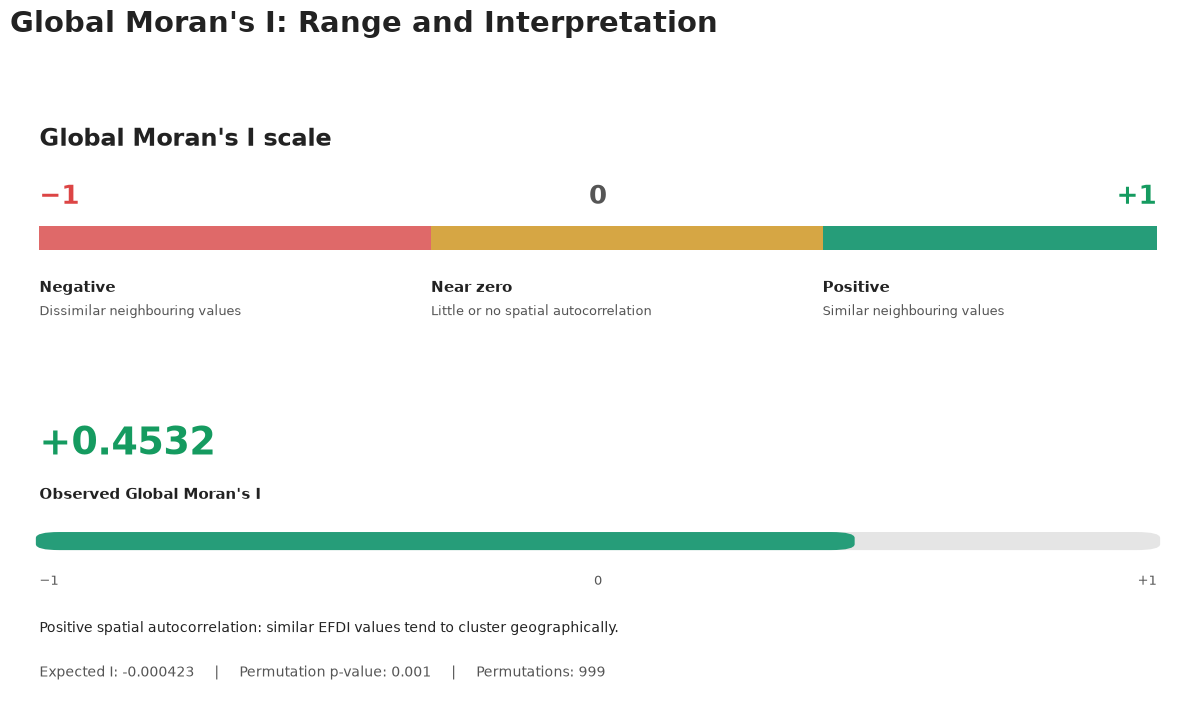

In [8]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

# -----------------------------------------
# 1. Global Moran's I results
# -----------------------------------------
moran_i = 0.4531533369
expected_i = -0.0004230118
p_value = 0.001

# -----------------------------------------
# 2. Figure setup - WHITE BACKGROUND
# -----------------------------------------
fig = plt.figure(figsize=(14, 8), facecolor="white")

fig.text(
    0.08, 0.94,
    "Global Moran's I: Range and Interpretation",
    fontsize=21,
    fontweight="bold",
    color="#222222"
)

# -----------------------------------------
# 3. First panel: Moran's I scale
# -----------------------------------------
ax1 = fig.add_axes([0.08, 0.56, 0.84, 0.29])
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.axis("off")

# Rounded white panel
panel1 = FancyBboxPatch(
    (0, 0), 1, 1,
    boxstyle="round,pad=0.015,rounding_size=0.035",
    facecolor="white",
    edgecolor="#cccccc",
    linewidth=1.2
)
ax1.add_patch(panel1)

ax1.text(
    0.025, 0.82,
    "Global Moran's I scale",
    fontsize=17,
    fontweight="bold",
    color="#222222"
)

# Scale labels
ax1.text(
    0.025, 0.57, "−1",
    fontsize=19,
    color="#dc4545",
    fontweight="bold"
)

ax1.text(
    0.50, 0.57, "0",
    fontsize=19,
    color="#555555",
    fontweight="bold",
    ha="center"
)

ax1.text(
    0.975, 0.57, "+1",
    fontsize=19,
    color="#159b60",
    fontweight="bold",
    ha="right"
)

# Three coloured sections
bar_y = 0.37
bar_h = 0.105

sections = [
    (0.025, 0.333, "#df6969"),
    (0.358, 0.333, "#d6a644"),
    (0.691, 0.284, "#269d79")
]

for x, width, color in sections:
    ax1.add_patch(
        Rectangle(
            (x, bar_y),
            width,
            bar_h,
            facecolor=color,
            edgecolor="none"
        )
    )

# Interpretation labels
labels = [
    (0.025, "Negative", "Dissimilar neighbouring values"),
    (0.358, "Near zero", "Little or no spatial autocorrelation"),
    (0.691, "Positive", "Similar neighbouring values")
]

for x, title, description in labels:
    ax1.text(
        x, 0.19, title,
        fontsize=11,
        color="#222222",
        fontweight="bold"
    )

    ax1.text(
        x, 0.09, description,
        fontsize=9,
        color="#555555"
    )

# -----------------------------------------
# 4. Second panel: Actual Moran's I result
# -----------------------------------------
ax2 = fig.add_axes([0.08, 0.09, 0.84, 0.37])
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.axis("off")

panel2 = FancyBboxPatch(
    (0, 0), 1, 1,
    boxstyle="round,pad=0.015,rounding_size=0.035",
    facecolor="white",
    edgecolor="#cccccc",
    linewidth=1.2
)
ax2.add_patch(panel2)

ax2.text(
    0.025, 0.87,
    f"{moran_i:+.4f}",
    fontsize=27,
    color="#159b60",
    fontweight="bold"
)

ax2.text(
    0.025, 0.72,
    "Observed Global Moran's I",
    fontsize=11,
    color="#222222",
    fontweight="bold"
)

# Position of Moran's I on the -1 to +1 scale
position = (moran_i + 1) / 2

# Background bar
ax2.add_patch(
    FancyBboxPatch(
        (0.025, 0.55), 0.95, 0.055,
        boxstyle="round,pad=0.003,rounding_size=0.02",
        facecolor="#e5e5e5",
        edgecolor="none"
    )
)

# Filled portion
ax2.add_patch(
    FancyBboxPatch(
        (0.025, 0.55), 0.95 * position, 0.055,
        boxstyle="round,pad=0.003,rounding_size=0.02",
        facecolor="#269d79",
        edgecolor="none"
    )
)

# Axis labels
ax2.text(
    0.025, 0.43, "−1",
    fontsize=9,
    color="#555555"
)

ax2.text(
    0.50, 0.43, "0",
    fontsize=9,
    color="#555555",
    ha="center"
)

ax2.text(
    0.975, 0.43, "+1",
    fontsize=9,
    color="#555555",
    ha="right"
)

# Interpretation
ax2.text(
    0.025, 0.27,
    "Positive spatial autocorrelation: similar EFDI values tend to cluster geographically.",
    fontsize=10,
    color="#222222"
)

# Statistical results
ax2.text(
    0.025, 0.12,
    f"Expected I: {expected_i:.6f}     |     "
    f"Permutation p-value: {p_value:.3f}     |     "
    "Permutations: 999",
    fontsize=10,
    color="#555555"
)

# -----------------------------------------
# 5. Save and display
# -----------------------------------------
plt.savefig(
    "Global_Morans_I_EFDI.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


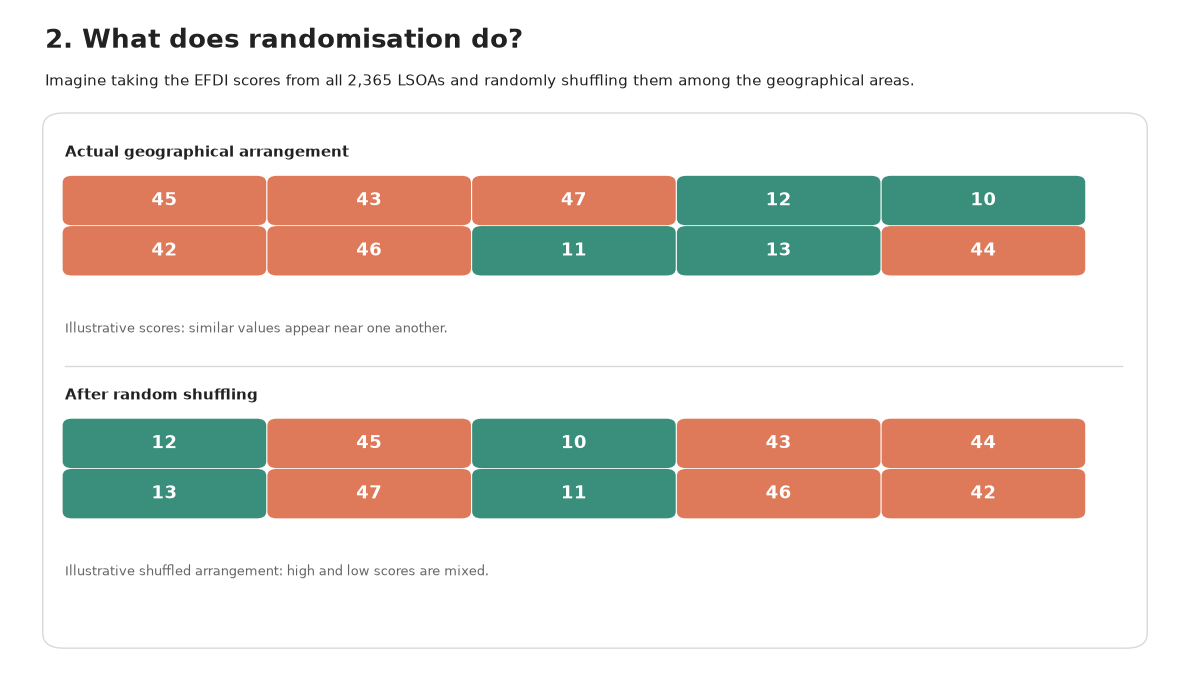

In [10]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --------------------------------------------------
# Data for illustration
# --------------------------------------------------
actual = [
    [45, 43, 47, 12, 10],
    [42, 46, 11, 13, 44]
]

randomised = [
    [12, 45, 10, 43, 44],
    [13, 47, 11, 46, 42]
]

# --------------------------------------------------
# Colours — WHITE BACKGROUND
# --------------------------------------------------
background = "#FFFFFF"
panel_color = "#FFFFFF"
high_color = "#DE7959"
low_color = "#398F7C"
text_color = "#222222"
muted_color = "#666666"
border_color = "#D9D9D9"

# --------------------------------------------------
# Figure
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.set_xlim(0, 10)
ax.set_ylim(0, 8)
ax.axis("off")

# Main heading
ax.text(
    0.3, 7.55,
    "2. What does randomisation do?",
    fontsize=19,
    fontweight="bold",
    color=text_color
)

ax.text(
    0.3, 7.1,
    "Imagine taking the EFDI scores from all 2,365 LSOAs "
    "and randomly shuffling them among the geographical areas.",
    fontsize=10.5,
    color=text_color
)

# --------------------------------------------------
# Main panel
# --------------------------------------------------
panel = FancyBboxPatch(
    (0.3, 0.4), 9.4, 6.35,
    boxstyle="round,pad=0.02,rounding_size=0.18",
    facecolor=panel_color,
    edgecolor=border_color,
    linewidth=1
)

ax.add_patch(panel)

# --------------------------------------------------
# Function to draw score grids
# --------------------------------------------------
def draw_grid(data, y_start):

    cell_width = 1.7
    cell_height = 0.55
    gap = 0.05
    x_start = 0.47

    for row_index, row in enumerate(data):

        for col_index, value in enumerate(row):

            x = x_start + col_index * (cell_width + gap)
            y = y_start - row_index * (cell_height + gap)

            colour = high_color if value >= 40 else low_color

            cell = FancyBboxPatch(
                (x, y),
                cell_width,
                cell_height,
                boxstyle="round,pad=0.02,rounding_size=0.08",
                facecolor=colour,
                edgecolor="none"
            )

            ax.add_patch(cell)

            ax.text(
                x + cell_width / 2,
                y + cell_height / 2,
                str(value),
                ha="center",
                va="center",
                fontsize=13,
                fontweight="bold",
                color="white"
            )

# --------------------------------------------------
# Actual geographical arrangement
# --------------------------------------------------
ax.text(
    0.47, 6.25,
    "Actual geographical arrangement",
    fontsize=11,
    fontweight="bold",
    color=text_color
)

draw_grid(actual, 5.45)

ax.text(
    0.47, 4.15,
    "Illustrative scores: similar values appear near one another.",
    fontsize=9,
    color=muted_color
)

# --------------------------------------------------
# Divider
# --------------------------------------------------
ax.plot(
    [0.47, 9.5],
    [3.75, 3.75],
    color=border_color,
    linewidth=1
)

# --------------------------------------------------
# Randomised arrangement
# --------------------------------------------------
ax.text(
    0.47, 3.35,
    "After random shuffling",
    fontsize=11,
    fontweight="bold",
    color=text_color
)

draw_grid(randomised, 2.55)

ax.text(
    0.47, 1.25,
    "Illustrative shuffled arrangement: high and low scores are mixed.",
    fontsize=9,
    color=muted_color
)

# --------------------------------------------------
# Display and save
# --------------------------------------------------
plt.tight_layout()

plt.savefig(
    "EFDI_Randomisation_White_Background.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()


In [11]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Extract results from the Moran's I analysis
# --------------------------------------------------
simulated = moran_global.sim

observed_i = moran_global.I
random_mean = simulated.mean()
random_min = simulated.min()
random_max = simulated.max()
p_value = moran_global.p_sim

# --------------------------------------------------
# Colours
# --------------------------------------------------
background = "#FFFFFF"
text_color = "#222222"
muted_color = "#666666"
hist_color = "#398F7C"
observed_color = "#DE7959"
reference_color = "#777777"

# --------------------------------------------------
# Create figure with two visualisations
# --------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

fig.patch.set_facecolor(background)

for ax in (ax1, ax2):
    ax.set_facecolor(background)

# --------------------------------------------------
# VISUAL 1: Randomisation distribution
# --------------------------------------------------
ax1.hist(
    simulated,
    bins=30,
    color=hist_color,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Reference line at zero
ax1.axvline(
    0,
    color=reference_color,
    linestyle="--",
    linewidth=1.5,
    label="Zero Moran's I"
)

ax1.set_title(
    "Randomisation Distribution",
    fontsize=14,
    fontweight="bold",
    color=text_color,
    pad=15
)

ax1.set_xlabel(
    "Simulated Moran's I",
    fontsize=11,
    color=text_color
)

ax1.set_ylabel(
    "Frequency",
    fontsize=11,
    color=text_color
)

ax1.text(
    0.04, 0.94,
    f"999 permutations\n"
    f"Mean: {random_mean:.4f}\n"
    f"Range: {random_min:.4f} to {random_max:.4f}",
    transform=ax1.transAxes,
    va="top",
    fontsize=10,
    color=text_color,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F2F2F2",
        edgecolor="#D9D9D9"
    )
)

ax1.legend(frameon=False, loc="upper right")

# --------------------------------------------------
# VISUAL 2: Actual Moran's I vs randomised range
# --------------------------------------------------
ax2.hlines(
    y=1,
    xmin=random_min,
    xmax=random_max,
    color=hist_color,
    linewidth=8,
    label="Randomisation range"
)

# Randomisation minimum and maximum
ax2.scatter(
    [random_min, random_max],
    [1, 1],
    color=hist_color,
    s=65,
    zorder=3
)

# Randomisation mean
ax2.scatter(
    random_mean,
    1,
    color="#222222",
    marker="|",
    s=250,
    linewidths=2,
    zorder=4
)

# Original observed Moran's I
ax2.scatter(
    observed_i,
    1,
    color=observed_color,
    edgecolor="black",
    linewidth=0.8,
    s=180,
    zorder=5,
    label="Original Moran's I"
)

# Annotate observed value
ax2.annotate(
    f"Original Moran's I\n{observed_i:.4f}",
    xy=(observed_i, 1),
    xytext=(-5, 45),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    fontweight="bold",
    color=observed_color,
    arrowprops=dict(
        arrowstyle="->",
        color=observed_color,
        linewidth=1.5
    )
)

# Annotate randomisation range
ax2.text(
    random_mean,
    0.83,
    f"Randomised range\n{random_min:.4f} to {random_max:.4f}",
    ha="center",
    va="top",
    fontsize=9,
    color=hist_color
)

ax2.set_title(
    "Observed vs Randomised Moran's I",
    fontsize=14,
    fontweight="bold",
    color=text_color,
    pad=15
)

ax2.set_xlabel(
    "Global Moran's I",
    fontsize=11,
    color=text_color
)

ax2.set_yticks([])
ax2.set_ylim(0.65, 1.35)
ax2.set_xlim(random_min - 0.03, observed_i + 0.08)

# P-value annotation
ax2.text(
    0.5, 0.08,
    f"Permutation p-value = {p_value:.3f}",
    transform=ax2.transAxes,
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=text_color,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F2F2F2",
        edgecolor="#D9D9D9"
    )
)

ax2.legend(
    loc="upper right",
    frameon=False
)

# --------------------------------------------------
# Overall formatting
# --------------------------------------------------
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D9D9D9")
    ax.spines["bottom"].set_color("#D9D9D9")
    ax.tick_params(colors=muted_color)

fig.suptitle(
    "Global Moran's I: EFDI Spatial Randomisation Test",
    fontsize=17,
    fontweight="bold",
    color=text_color,
    y=1.02
)

plt.tight_layout()

# Save figure
plt.savefig(
    "Global_Morans_I_Randomisation_Analysis.png",
    dpi=300,
    facecolor=background,
    bbox_inches="tight"
)

plt.show()


NameError: name 'moran_global' is not defined